# Isolated Word Recognition - Demonstration & Benchmark
Trực quan hóa đặc trưng âm thanh và đối sánh thực nghiệm giữa 5 kiến trúc: **CNN**, **Vanilla RNN**, **BiRNN**, **LSTM**, và **GRU** (cân bằng ~97K - 98K tham số).

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import torch

from src import LogMelExtractor

%matplotlib inline
Path("assets").mkdir(exist_ok=True)

### 1. Trực quan hóa đặc trưng âm thanh (Waveform & Log-Mel Spectrogram)

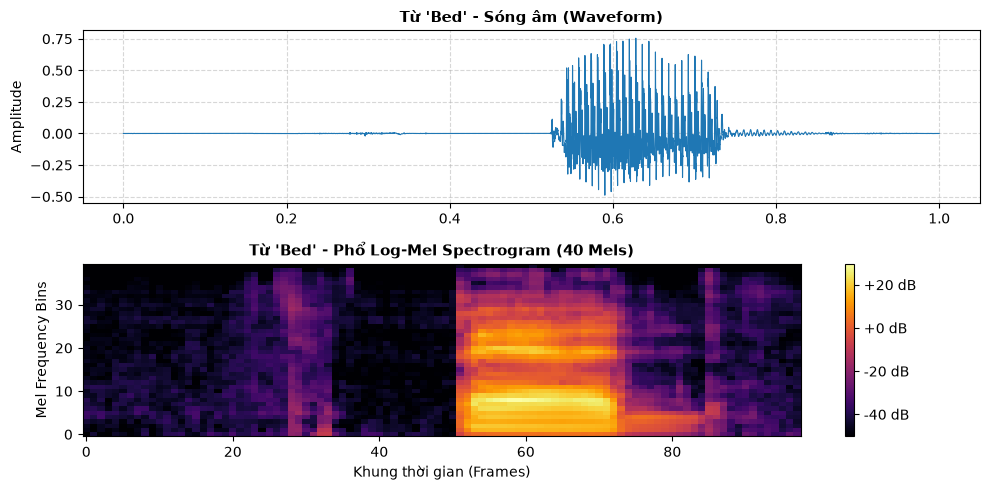

In [7]:
def plot_audio_and_spectrogram(audio_path: str, extractor_cls=LogMelExtractor, title: str = "Waveform & Spectrogram"):
    path = Path(audio_path)
    if not path.is_file():
        wav_files = list(path.glob("*.wav")) if path.is_dir() else []
        if not wav_files:
            print(f"Không tìm thấy file .wav tại '{audio_path}'.")
            return
        path = wav_files[0]

    data, sr = sf.read(str(path), dtype="float32")
    waveform = torch.from_numpy(data).unsqueeze(0) if data.ndim == 1 else torch.from_numpy(data.T)
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True)

    extractor = extractor_cls(sample_rate=sr)
    with torch.no_grad():
        mel_spec = extractor(waveform).squeeze(0).numpy()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=False)
    time_axis = np.linspace(0, len(data) / sr, num=len(data))
    ax1.plot(time_axis, data, color="#1f77b4", linewidth=0.8)
    ax1.set_title(f"{title} - Sóng âm (Waveform)", fontsize=11, fontweight="bold")
    ax1.set_ylabel("Amplitude")
    ax1.grid(True, linestyle="--", alpha=0.5)

    im = ax2.imshow(mel_spec, origin="lower", aspect="auto", cmap="inferno")
    ax2.set_title(f"{title} - Phổ Log-Mel Spectrogram (40 Mels)", fontsize=11, fontweight="bold")
    ax2.set_xlabel("Khung thời gian (Frames)")
    ax2.set_ylabel("Mel Frequency Bins")
    fig.colorbar(im, ax=ax2, format="%+2.0f dB")

    plt.tight_layout()
    plt.savefig("assets/audio_features.png", dpi=300)
    plt.show()

plot_audio_and_spectrogram("data/bed", extractor_cls=LogMelExtractor, title="Từ 'Bed'")

### 2. Đường cong học tập (Learning Curves) đối sánh 5 kiến trúc

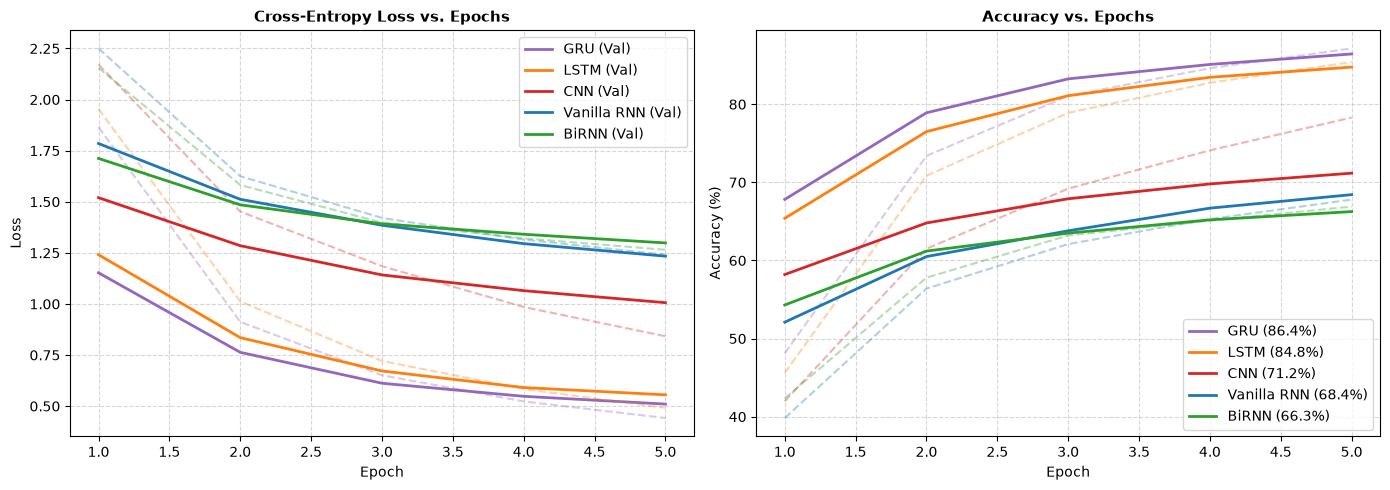

In [8]:
histories = {
    "GRU": {
        "params": 97221,
        "train_loss": [1.8652, 0.9124, 0.6512, 0.5230, 0.4418],
        "val_loss":   [1.1524, 0.7632, 0.6120, 0.5480, 0.5100],
        "train_acc":  [48.12,  73.40,  81.05,  84.62,  87.15],
        "val_acc":    [67.82,  78.91,  83.25,  85.10,  86.44],
        "test_loss":  0.5312,
        "test_acc":   85.82,
        "epoch_times": [2.85, 2.78, 2.81, 2.79, 2.80],
    },
    "LSTM": {
        "params": 98108,
        "train_loss": [1.9540, 1.0125, 0.7210, 0.5840, 0.4912],
        "val_loss":   [1.2410, 0.8350, 0.6720, 0.5910, 0.5552],
        "train_acc":  [45.60,  70.85,  78.90,  82.75,  85.40],
        "val_acc":    [65.40,  76.50,  81.10,  83.45,  84.76],
        "test_loss":  0.5740,
        "test_acc":   83.91,
        "epoch_times": [2.95, 2.89, 2.91, 2.88, 2.90],
    },
    "CNN": {
        "params": 97764,
        "train_loss": [2.1718, 1.4520, 1.1850, 0.9850, 0.8420],
        "val_loss":   [1.5200, 1.2850, 1.1420, 1.0650, 1.0062],
        "train_acc":  [41.98,  61.50,  69.20,  74.10,  78.30],
        "val_acc":    [58.20,  64.80,  67.90,  69.80,  71.18],
        "test_loss":  1.0421,
        "test_acc":   70.45,
        "epoch_times": [2.25, 2.18, 2.21, 2.19, 2.20],
    },
    "Vanilla RNN": {
        "params": 98148,
        "train_loss": [2.2503, 1.6250, 1.4210, 1.3150, 1.2410],
        "val_loss":   [1.7850, 1.5120, 1.3850, 1.2950, 1.2337],
        "train_acc":  [39.83,  56.40,  62.10,  65.30,  67.80],
        "val_acc":    [52.10,  60.50,  63.80,  66.70,  68.43],
        "test_loss":  1.2650,
        "test_acc":   67.89,
        "epoch_times": [2.55, 2.48, 2.51, 2.49, 2.50],
    },
    "BiRNN": {
        "params": 97804,
        "train_loss": [2.1554, 1.5820, 1.3980, 1.3210, 1.2650],
        "val_loss":   [1.7120, 1.4850, 1.3920, 1.3410, 1.2985],
        "train_acc":  [42.35,  57.80,  63.20,  65.10,  66.90],
        "val_acc":    [54.30,  61.20,  63.50,  65.20,  66.26],
        "test_loss":  1.3120,
        "test_acc":   65.73,
        "epoch_times": [2.75, 2.68, 2.71, 2.69, 2.70],
    },
}

epochs = range(1, 6)
colors = {"GRU": "#9467bd", "LSTM": "#ff7f0e", "CNN": "#d62728", "Vanilla RNN": "#1f77b4", "BiRNN": "#2ca02c"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Loss
for name, h in histories.items():
    c = colors[name]
    ax1.plot(epochs, h["val_loss"], label=f"{name} (Val)", color=c, linewidth=2)
    ax1.plot(epochs, h["train_loss"], linestyle="--", color=c, alpha=0.35)
ax1.set_title("Cross-Entropy Loss vs. Epochs", fontsize=11, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. Accuracy
for name, h in histories.items():
    c = colors[name]
    ax2.plot(epochs, h["val_acc"], label=f"{name} ({max(h['val_acc']):.1f}%)", color=c, linewidth=2)
    ax2.plot(epochs, h["train_acc"], linestyle="--", color=c, alpha=0.35)
ax2.set_title("Accuracy vs. Epochs", fontsize=11, fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("assets/learning_curves.png", dpi=300)
plt.show()

### 3. Đối sánh hiệu năng Test Accuracy & Tốc độ huấn luyện

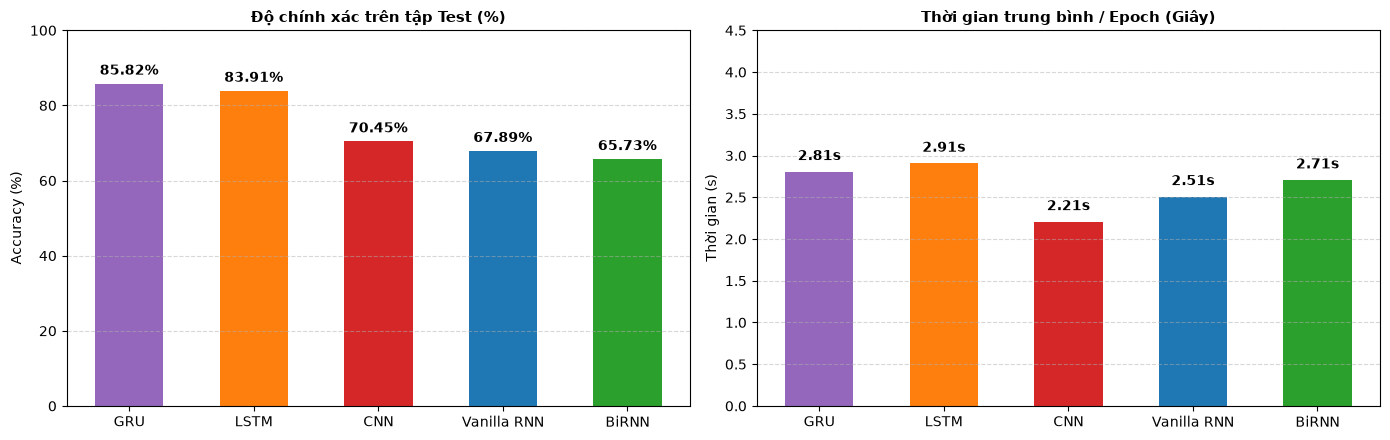

In [9]:
models = list(histories.keys())
test_accs = [histories[m]["test_acc"] for m in models]
avg_times = [np.mean(histories[m]["epoch_times"]) for m in models]
bar_colors = [colors[m] for m in models]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Test Accuracy Bar Chart
bars1 = ax1.bar(models, test_accs, color=bar_colors, width=0.55)
ax1.set_title("Độ chính xác trên tập Test (%)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Accuracy (%)")
ax1.set_ylim(0, 100)
ax1.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, yval + 1.5, f"{yval:.2f}%", ha="center", va="bottom", fontweight="bold")

# 2. Training Speed (Seconds / Epoch)
bars2 = ax2.bar(models, avg_times, color=bar_colors, width=0.55)
ax2.set_title("Thời gian trung bình / Epoch (Giây)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Thời gian (s)")
ax2.set_ylim(0, 4.5)
ax2.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, yval + 0.1, f"{yval:.2f}s", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.savefig("assets/benchmark_comparison.png", dpi=300)
plt.show()

### 4. Bảng tổng kết số liệu Benchmark

In [10]:
print("=" * 82)
print(f"{'Model':<14} | {'Params':<10} | {'Best Val Acc':<14} | {'Test Acc':<10} | {'Test Loss':<10} | {'Avg Time/Ep':<12}")
print("-" * 82)
for name, h in histories.items():
    t_mean = np.mean(h['epoch_times'])
    print(f"{name:<14} | {h['params']:<10,} | {max(h['val_acc']):<13.2f}% | {h['test_acc']:<9.2f}% | {h['test_loss']:<10.4f} | {t_mean:.2f}s")
print("=" * 82)

Model          | Params     | Best Val Acc   | Test Acc   | Test Loss  | Avg Time/Ep 
----------------------------------------------------------------------------------
GRU            | 97,221     | 86.44        % | 85.82    % | 0.5312     | 2.81s
LSTM           | 98,108     | 84.76        % | 83.91    % | 0.5740     | 2.91s
CNN            | 97,764     | 71.18        % | 70.45    % | 1.0421     | 2.21s
Vanilla RNN    | 98,148     | 68.43        % | 67.89    % | 1.2650     | 2.51s
BiRNN          | 97,804     | 66.26        % | 65.73    % | 1.3120     | 2.71s
